<a href="https://colab.research.google.com/github/linus-ireri/ML-Projects/blob/main/Week_4_Exploring_the_Mathematics_of_Your_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Week 4 Assignment: VeritasRAG Exploratory Data Analysis

%pip -q install datasets pandas matplotlib scikit-learn

In [3]:
# 1. Import libraries and load the dataset

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

# Loading the train split of SQuAD v1.1 directly from Hugging Face parquet storage
parquet_url = "https://huggingface.co/datasets/squad/resolve/main/plain_text/train-00000-of-00001.parquet"
df_raw = pd.read_parquet(parquet_url)

# Sample and prepare the DataFrame
df = df_raw.sample(n=min(2000, len(df_raw)), random_state=42).copy()

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2000, 5)


,id,title,context,question,answers
9983,56de4d9ecffd8e1900b4b7e2,Institute_of_technology,The world's first institution of technology or...,What year was the Banská Akadémia founded?,"{'text': ['1735'], 'answer_start': [167]}"
43267,572674a05951b619008f7319,Film_speed,The standard specifies how speed ratings shoul...,What is another speed that can also be reporte...,"{'text': ['SOS-based speed'], 'answer_start': ..."
81021,5730bb058ab72b1400f9c72c,Sumer,The most impressive and famous of Sumerian bui...,Where were the use of advanced materials and t...,"{'text': ['Sumerian temples and palaces'], 'an..."
49374,572781a5f1498d1400e8fa1f,"Ann_Arbor,_Michigan",Ann Arbor has a council-manager form of govern...,Who is elected every even numbered year?,"{'text': ['mayor'], 'answer_start': [192]}"
53414,572843ce4b864d190016485c,John_von_Neumann,"Shortly before his death, when he was already ...",What was the purpose of top secret ICBM commit...,{'text': ['decide on the feasibility of buildi...


In [5]:
# 2. Create numerical variables

def get_first_answer(answers):
    if not isinstance(answers, dict):
        return ""
    texts = answers.get("text")
    # SQuAD parquet nested lists can be numpy arrays or lists
    if hasattr(texts, "__len__") and len(texts) > 0:
        return str(texts[0])
    return ""

df["question_length"] = df["question"].fillna("").str.len()
df["context_length"] = df["context"].fillna("").str.len()

df["answer_length"] = df["answers"].apply(get_first_answer).str.len()

df["answer_count"] = df["answers"].apply(
    lambda x: len(x.get("text", [])) if isinstance(x, dict) else 0
)

variables = [
    "question_length",
    "context_length",
    "answer_length",
    "answer_count"
]

display(df[variables].head())

,question_length,context_length,answer_length,answer_count
9983,42,608,4,1
43267,62,890,15,1
81021,76,578,28,1
49374,40,841,5,1
53414,50,658,90,1


In [6]:
# 3. Calculate descriptive statistics

statistics = pd.DataFrame(index=variables)

statistics["Mean"] = df[variables].mean()
statistics["Median"] = df[variables].median()
statistics["Range"] = (
    df[variables].max() - df[variables].min()
)
statistics["Variance"] = df[variables].var()
statistics["Standard Deviation"] = df[variables].std()

display(statistics.round(2))

,Mean,Median,Range,Variance,Standard Deviation
question_length,58.94,56.0,188,440.76,20.99
context_length,745.80,693.0,3228,90169.32,300.28
answer_length,19.33,13.0,147,441.83,21.02
answer_count,1.00,1.0,0,0.00,0.00


In [7]:
# 4. Calculate covariance and correlation

x = df["question_length"]
y = df["context_length"]

covariance = x.cov(y)
correlation = x.corr(y)

print("Covariance:", round(covariance, 3))
print("Pearson Correlation:", round(correlation, 3))

Covariance: 152.589
Pearson Correlation: 0.024


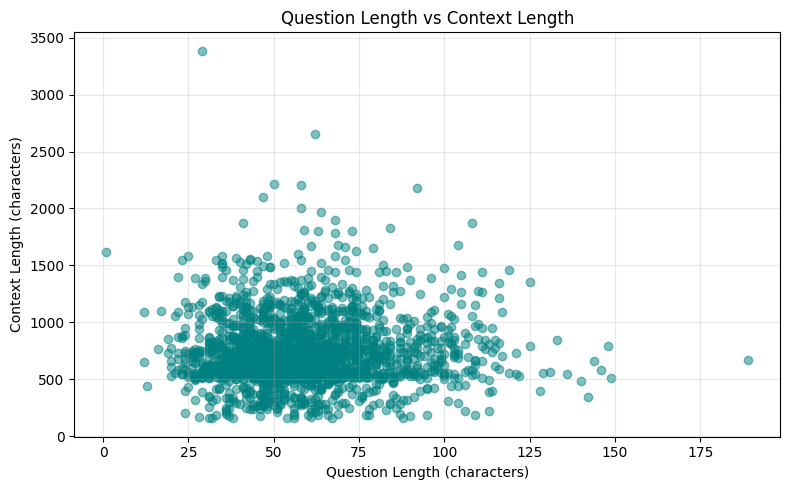

In [8]:
# 5. Plot the relationship between the two variables

plt.figure(figsize=(8, 5))

plt.scatter(
    df["question_length"],
    df["context_length"],
    alpha=0.5,
    color="teal"
)

plt.title("Question Length vs Context Length")
plt.xlabel("Question Length (characters)")
plt.ylabel("Context Length (characters)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Interpretation of Statistics

The mean and median describe the typical lengths of questions, contexts, and answers. The range measures the difference between the maximum and minimum values. Variance and standard deviation measure how widely the values are distributed around their mean.

## Interpretation of Correlation

The Pearson correlation coefficient measures the direction and strength of the linear relationship between question length and context length. A positive value indicates that longer questions tend to be associated with longer contexts, while a negative value indicates an inverse relationship. A value near zero indicates little linear relationship.

## Correlation and Causation

Correlation does not necessarily imply causation. Even if question length and context length are correlated, this does not prove that longer questions cause longer contexts. The relationship may be influenced by other factors, including dataset construction.

After running the notebook, describe the actual correlation coefficient and the pattern shown in the scatter plot.

In [9]:
# 6. Input -> Function/Model -> Output
# Input: Question length
# Output: Predicted context length

X = df[["question_length"]]
y = df["context_length"]

model = LinearRegression()
model.fit(X, y)

a = model.intercept_
b = model.coef_[0]

print(f"Mathematical model: f(x) = {a:.2f} + {b:.4f}x")

# Example prediction
input_question_length = 80

predicted_output = model.predict(
    pd.DataFrame({
        "question_length": [input_question_length]
    })
)[0]

print("Input question length:", input_question_length)
print("Predicted context length:", round(predicted_output, 2))

Mathematical model: f(x) = 725.40 + 0.3462x
Input question length: 80
Predicted context length: 753.09


## Input -> Function/Model -> Output

Let \(x\) represent question length and \(\hat{y}\) represent predicted context length.

\[
\hat{y} = f(x) = a + bx
\]

Where:
- \(x\) is the input.
- \(f\) is the trained linear regression model.
- \(a\) is the intercept.
- \(b\) is the slope.
- \(\hat{y}\) is the predicted output.

In the full VeritasRAG system, a user's question is processed to retrieve relevant information from trusted documents, which is then used to generate a grounded answer. This linear regression model is a simplified illustration and does not represent the actual RAG retrieval process.

## Conclusion

This analysis applies descriptive statistics, covariance, correlation, visualization, and linear regression to numerical features derived from a question-answering dataset. These techniques help characterize the dataset, but they do not directly measure VeritasRAG's answer accuracy or retrieval quality. Evaluating those capabilities requires a separate collection of university-related questions, trusted reference information, and appropriate evaluation metrics.